# 6 — Residualized features: predict age from what the nuisances cannot explain

Notebooks 1 and 2 control the nuisances in two different ways, and neither combines the
features after cleaning them:

* **notebook 1** residualizes each feature (and age) on the nuisances, then tests it **alone**
  (partial Spearman);
* **notebook 2** feeds the forest nuisances **and** raw features side by side, so a feature can
  stand in for a nuisance (amplitude partly encodes noise floor) and the gain over
  nuisance-only is hard to read.

This notebook does **nuisance regression, then prediction**:

1. **Residualize.** For each of the 23 features, fit an OLS regression on the nuisance design
   (galaxy dummies, cadence, sectors, length, noise floor, brightness, radius, dec, galactic
   latitude) and keep the residual: *how unusual is this feature for a cluster observed like
   this?* The residuals have no linear relation to any nuisance by construction.
2. **Predict.** Fit a ridge regression on all 23 residualized features together and predict
   log age out of fold.

Because the cleaned features carry no (linear) galaxy or observing-setup information, they cannot
use the "LMC is young" shortcut. **The null for this test is R² = 0**, not the nuisance-only
score — any skill above zero is light-curve information independent of the nuisances.

Two versions of the target:

| model | features | target | reads as |
|---|---|---|---|
| **residualized → age** | residualized | log age | share of *total* age variance the cleaned light curves explain |
| **residualized → residual age** | residualized | log age, also residualized | partial R²: share of the age variance the nuisances *leave unexplained* |

and three references on the same folds: nuisance-only, raw features only, nuisances + raw
features (the linear analogue of notebook 2's nested comparison).

**Leakage guard.** The residualizing regression is fit on the training clusters of each fold and
applied unchanged to the test clusters, so the test set never helps define "expected given the
nuisances". Same 80/20 holdout and 5×5 repeated K-fold as notebooks 2, 4 and 5.

**Limit.** OLS residualization removes *linear* nuisance dependence only. A linear predictor in
step 2 cannot exploit what curvature is left, which is why this notebook stays linear; a forest on
the residuals would need its own check.

In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('.'))
import analysis_utils as A

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import RepeatedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import r2_score

GT = '/astro/users/cgwill/TESS_Cluster_Age_ML/GenerateTable_CGW/data'
TABLE = f'{GT}/cluster_table_Sep23_all_combos_le3sectors.pkl'
SEED = 0
N_PERM = 300
print('using', os.path.basename(TABLE))
pd.set_option('display.width', 220)
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'axes.axisbelow': True,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})

using cluster_table_Sep23_all_combos_le3sectors.pkl


In [2]:
rows = A.load_rows(TABLE)
meta = A.cluster_metadata()
clusters = A.cluster_table(rows, meta=meta)
clusters = clusters[clusters.age.notna()].reset_index(drop=True)
del rows

FEATURES  = [c for c, _, _ in A.feature_columns(clusters)]
NUISANCES = [n for n, _, _ in A.NUISANCE_SPEC if n in clusters.columns]
X_nuis = A.design_matrix(clusters, NUISANCES, add_const=False).astype(float)
X_feat = clusters[FEATURES].apply(pd.to_numeric, errors='coerce')
y = clusters.age.to_numpy(float)
origin = clusters.origin.to_numpy()
N_NUIS = X_nuis.shape[1]
print(f'{len(clusters)} clusters | {N_NUIS} nuisance columns | {len(FEATURES)} features')
print('missing values  nuisances:', int(X_nuis.isna().sum().sum()),
      '| features:', int(X_feat.isna().sum().sum()), '(median-imputed inside each fold)')

17233 rows, 348 clusters from cluster_table_Sep23_all_combos_le3sectors.pkl
rows per cluster: median 3, max 409


348 clusters | 10 nuisance columns | 23 features
missing values  nuisances: 0 | features: 132 (median-imputed inside each fold)


## 1 · The residualizer

A scikit-learn transformer, so it lives inside the fold loop: `fit` learns the medians (for
imputation) and the OLS coefficients feature-on-nuisances from the training clusters only;
`transform` applies them to any clusters. Input columns are `[nuisances | features]`; output is
the residualized features.

In [3]:
class NuisanceResidualizer(BaseEstimator, TransformerMixin):
    """Features minus their OLS prediction from the nuisances (fit on training data only)."""

    def __init__(self, n_nuis):
        self.n_nuis = n_nuis

    def _split(self, X):
        X = np.asarray(X, float)
        Nu, F = X[:, :self.n_nuis], X[:, self.n_nuis:]
        Nu = np.where(np.isnan(Nu), self.nmed_, Nu)
        F = np.where(np.isnan(F), self.fmed_, F)
        return np.column_stack([np.ones(len(Nu)), Nu]), F

    def fit(self, X, y=None):
        X = np.asarray(X, float)
        self.nmed_ = np.nanmedian(X[:, :self.n_nuis], axis=0)
        self.fmed_ = np.nanmedian(X[:, self.n_nuis:], axis=0)
        D, F = self._split(X)
        self.beta_, *_ = np.linalg.lstsq(D, F, rcond=None)
        return self

    def transform(self, X):
        D, F = self._split(X)
        return F - D @ self.beta_


def ridge():
    return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 30)))


def residualize_target(Xn_tr, y_tr, Xn_te, y_te):
    """Age minus its OLS prediction from the nuisances, coefficients from training clusters."""
    imp = SimpleImputer(strategy='median').fit(Xn_tr)
    D_tr = np.column_stack([np.ones(len(y_tr)), imp.transform(Xn_tr)])
    D_te = np.column_stack([np.ones(len(y_te)), imp.transform(Xn_te)])
    b, *_ = np.linalg.lstsq(D_tr, y_tr, rcond=None)
    return y_tr - D_tr @ b, y_te - D_te @ b


# every model is (input columns, estimator, residualize the target?)
XNF = pd.concat([X_nuis, X_feat], axis=1)
MODELS = {
    'nuisance-only':          ('nuis', lambda: make_pipeline(SimpleImputer(strategy='median'), ridge()), False),
    'raw features':           ('feat', lambda: make_pipeline(SimpleImputer(strategy='median'), ridge()), False),
    'nuisances + raw':        ('both', lambda: make_pipeline(SimpleImputer(strategy='median'), ridge()), False),
    'residualized → age':     ('both', lambda: make_pipeline(NuisanceResidualizer(N_NUIS), ridge()), False),
    'residualized → resid age': ('both', lambda: make_pipeline(NuisanceResidualizer(N_NUIS), ridge()), True),
}
COLS = {'nuis': X_nuis, 'feat': X_feat, 'both': XNF}


def fit_score(name, tr, te, yv):
    cols, make, resid_y = MODELS[name]
    X = COLS[cols].to_numpy(float)
    y_tr, y_te = yv[tr], yv[te]
    if resid_y:
        y_tr, y_te = residualize_target(X_nuis.to_numpy(float)[tr], y_tr,
                                        X_nuis.to_numpy(float)[te], y_te)
    m = make().fit(X[tr], y_tr)
    return r2_score(y_te, m.predict(X[te])), m

## 2 · Does the residualizer actually remove the nuisances?

Fit on one training fold, applied to its test fold. Train-side correlations are zero by
construction; the test side shows how well the linear fit generalises to unseen clusters.

In [4]:
HOLD = A.holdout_by_cluster(clusters.name.values, y=y, frac=0.2, seed=SEED)   # same as nb 2/4/5
POOL = np.where(~HOLD)[0]
print(f'CV pool {len(POOL)} clusters | holdout {HOLD.sum()} clusters')

tr_i, te_i = next(RepeatedKFold(n_splits=5, n_repeats=1, random_state=SEED).split(POOL))
tr, te = POOL[tr_i], POOL[te_i]
res = NuisanceResidualizer(N_NUIS).fit(XNF.to_numpy(float)[tr])
nu_imp = SimpleImputer(strategy='median').fit(X_nuis.to_numpy(float)[tr])

def max_abs_corr(Rf, Nu):
    c = np.corrcoef(np.column_stack([Rf, Nu]), rowvar=False)[:Rf.shape[1], Rf.shape[1]:]
    return np.nanmax(np.abs(c), axis=1)

NU, FE = X_nuis.to_numpy(float), X_feat.to_numpy(float)
raw_te = SimpleImputer(strategy='median').fit(FE[tr]).transform(FE[te])
leak = pd.DataFrame({
    'raw, test':          max_abs_corr(raw_te, nu_imp.transform(NU[te])),
    'residual, train':    max_abs_corr(res.transform(XNF.to_numpy(float)[tr]), nu_imp.transform(NU[tr])),
    'residual, test':     max_abs_corr(res.transform(XNF.to_numpy(float)[te]), nu_imp.transform(NU[te])),
}, index=FEATURES).sort_values('raw, test', ascending=False)
display(leak.round(3).head(10))
print('CONCLUSION —')
print(f'  Strongest raw feature-nuisance |r| on the test fold: {leak["raw, test"].max():.2f}; after '
      f'residualizing: {leak["residual, test"].max():.2f} (median {leak["residual, test"].median():.2f}).')
print(f'  With ~{len(te)} test clusters, |r| up to ~{2/np.sqrt(len(te)):.2f} is sampling noise, so what remains is')
print('  the linear fit not transferring perfectly to unseen clusters, not a systematic leak.')

CV pool 278 clusters | holdout 70 clusters


,"raw, test","residual, train","residual, test"
rn_log10_N,0.804,0.028,0.142
stetson_j_gap_aware,0.679,0.028,0.143
sigma_mad,0.675,0.043,0.143
rn_alpha,0.647,0.021,0.071
gp_period_strongest,0.561,0.078,0.215
gp_jitter,0.556,0.076,0.247
gp_rn_wn_ratio,0.535,0.008,0.131
intrinsic_rms,0.492,0.034,0.128
intrinsic_std,0.492,0.034,0.129
excess_var,0.492,0.034,0.129


CONCLUSION —
  Strongest raw feature-nuisance |r| on the test fold: 0.80; after residualizing: 0.32 (median 0.20).
  With ~56 test clusters, |r| up to ~0.27 is sampling noise, so what remains is
  the linear fit not transferring perfectly to unseen clusters, not a systematic leak.


## 3 · Cross-validated comparison

5-fold × 5 repeats on the 80% pool; one R² per fold so the scatter is visible. Ridge strength is
chosen by efficient leave-one-out inside each training fold.

In [5]:
CV = list(RepeatedKFold(n_splits=5, n_repeats=5, random_state=SEED).split(POOL))
folds, coefs = {m: [] for m in MODELS}, []
for tr_i, te_i in CV:
    tr, te = POOL[tr_i], POOL[te_i]
    for name in MODELS:
        r2, m = fit_score(name, tr, te, y)
        folds[name].append(r2)
        if name == 'residualized → age':
            coefs.append(m[-1][-1].coef_)
folds = {k: np.array(v) for k, v in folds.items()}
coefs = pd.DataFrame(coefs, columns=FEATURES)

holdout = {}
for name in MODELS:
    holdout[name], _ = fit_score(name, POOL, np.where(HOLD)[0], y)

res_tab = pd.DataFrame({'cv_r2': {k: v.mean() for k, v in folds.items()},
                        'cv_r2_sd': {k: v.std() for k, v in folds.items()},
                        'holdout_r2': holdout})
display(res_tab.round(3))
d_nested = folds['nuisances + raw'] - folds['nuisance-only']
print(f'linear nested gain (nuisances + raw − nuisance-only): {d_nested.mean():+.3f} ± {d_nested.std():.3f} per fold')
print("notebook 2 (forest) gave +0.046 on the same pool")

,cv_r2,cv_r2_sd,holdout_r2
nuisance-only,0.056,0.098,0.070
raw features,0.044,0.095,0.074
nuisances + raw,0.108,0.084,0.109
residualized → age,0.005,0.056,0.042
residualized → resid age,0.015,0.058,0.059


linear nested gain (nuisances + raw − nuisance-only): +0.052 ± 0.058 per fold
notebook 2 (forest) gave +0.046 on the same pool


## 4 · Is the residualized skill more than chance?

Two nulls, because they protect against different things:

* **Within-galaxy shuffle** (as in notebooks 2–5): ages permuted inside each galaxy. This keeps
  the galaxy–age link but **breaks age's link to the other nuisances** (sectors, radius, noise
  floor). Any nuisance information that leaks past the linear residualization then counts as
  signal, so this null is too lenient for this test.
* **Freedman–Lane** (the standard null for a partial test): fit age on the nuisances, permute
  only the **residuals**, add them back to the fitted values. Every linear age–nuisance relation
  is kept; only the part of age the nuisances do not explain is scrambled. **This is the one to
  quote.**

Both run on the same folds as §3. The residualized models sit below zero under either null: a
ridge fit to noise predicts worse than the mean.

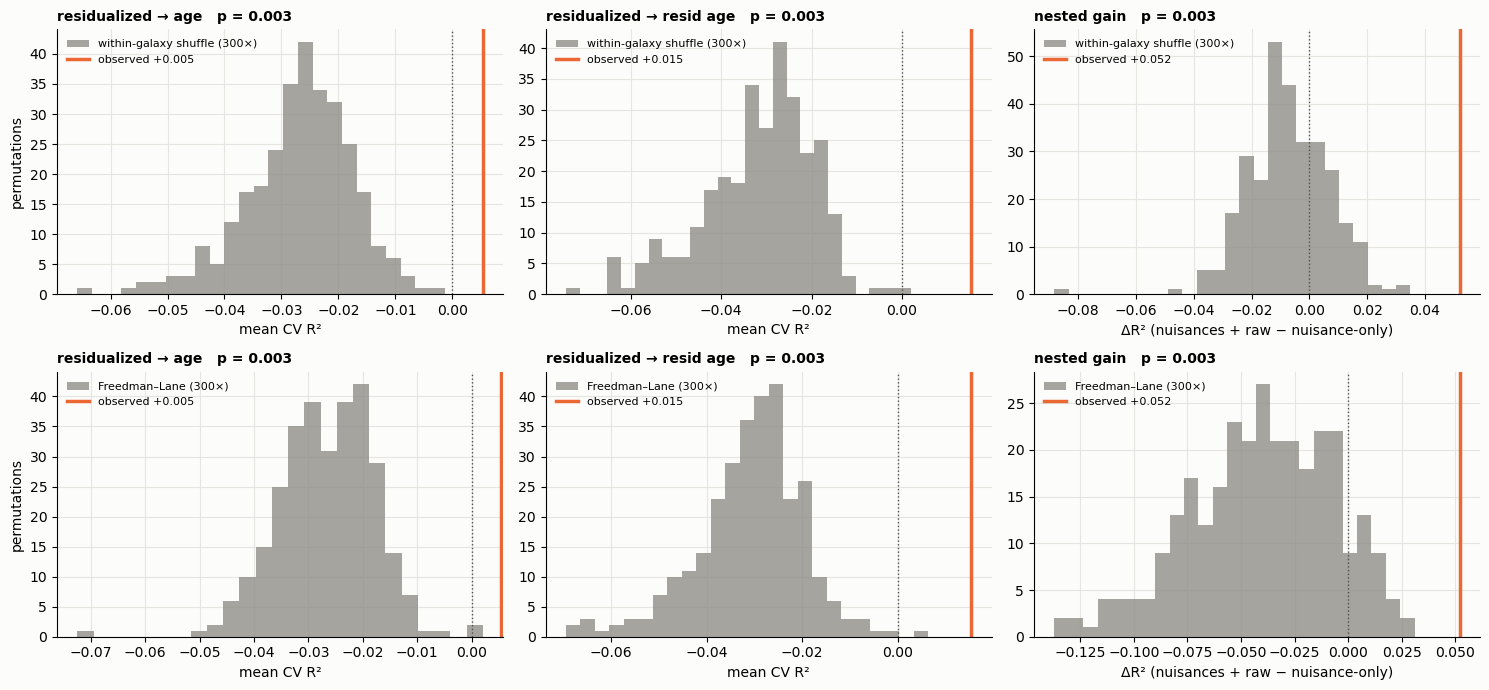

CONCLUSION —
  [within-galaxy shuffle]
    residualized → age         observed +0.005 | null -0.027 ± 0.009 | p = 0.003
    residualized → resid age   observed +0.015 | null -0.032 ± 0.012 | p = 0.003
    nested gain                observed +0.052 | null -0.007 ± 0.014 | p = 0.003
  [Freedman–Lane]
    residualized → age         observed +0.005 | null -0.027 ± 0.009 | p = 0.003
    residualized → resid age   observed +0.015 | null -0.031 ± 0.011 | p = 0.003
    nested gain                observed +0.052 | null -0.040 ± 0.033 | p = 0.003
  Quote Freedman–Lane: it keeps the age–nuisance relations, so only light-curve information
  the (linear) nuisances cannot reproduce can beat it.


In [6]:
TESTED = ['residualized → age', 'residualized → resid age']
KEYS = TESTED + ['nested gain']
rng = np.random.default_rng(SEED)
pool_origin = origin[POOL]

def shuffled_within_galaxy():
    yp = y.copy()
    for o in np.unique(pool_origin):
        i = POOL[pool_origin == o]
        yp[i] = rng.permutation(y[i])
    return yp

# Freedman–Lane: age = fitted(nuisances) + residual; permute the residual only
_imp = SimpleImputer(strategy='median').fit(X_nuis.to_numpy(float)[POOL])
_D = np.column_stack([np.ones(len(POOL)), _imp.transform(X_nuis.to_numpy(float)[POOL])])
_b, *_ = np.linalg.lstsq(_D, y[POOL], rcond=None)
_fit, _res = _D @ _b, y[POOL] - _D @ _b

def freedman_lane():
    yp = y.copy()
    yp[POOL] = _fit + rng.permutation(_res)
    return yp

def run_null(make_y):
    out = {k: [] for k in KEYS}
    for _ in range(N_PERM):
        yp = make_y()
        acc = {m: [] for m in TESTED + ['nuisance-only', 'nuisances + raw']}
        for tr_i, te_i in CV:
            tr, te = POOL[tr_i], POOL[te_i]
            for name in acc:
                acc[name].append(fit_score(name, tr, te, yp)[0])
        for m in TESTED:
            out[m].append(np.mean(acc[m]))
        out['nested gain'].append(np.mean(acc['nuisances + raw']) - np.mean(acc['nuisance-only']))
    return {k: np.array(v) for k, v in out.items()}

nulls = {'within-galaxy shuffle': run_null(shuffled_within_galaxy),
         'Freedman–Lane': run_null(freedman_lane)}

obs = {m: folds[m].mean() for m in TESTED}
obs['nested gain'] = d_nested.mean()
pvals = {nn: {k: (np.sum(nd[k] >= obs[k]) + 1) / (N_PERM + 1) for k in KEYS} for nn, nd in nulls.items()}

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for r, (nn, nd) in enumerate(nulls.items()):
    for ax, k in zip(axes[r], KEYS):
        ax.hist(nd[k], bins=25, color='#8f8e88', alpha=.8, label=f'{nn} ({N_PERM}×)')
        ax.axvline(obs[k], color='#eb6834', lw=2.5, label=f'observed {obs[k]:+.3f}')
        ax.axvline(0, color='#52514e', lw=1, ls=':')
        ax.set_title(f'{k}   p = {pvals[nn][k]:.3f}', loc='left', fontweight='bold', fontsize=10)
        ax.set_xlabel('mean CV R²' if k != 'nested gain' else 'ΔR² (nuisances + raw − nuisance-only)')
        ax.legend(fontsize=8)
    axes[r, 0].set_ylabel('permutations')
plt.tight_layout(); plt.show()

print('CONCLUSION —')
for nn, nd in nulls.items():
    print(f'  [{nn}]')
    for k in KEYS:
        print(f'    {k:<26} observed {obs[k]:+.3f} | null {nd[k].mean():+.3f} ± {nd[k].std():.3f} | p = {pvals[nn][k]:.3f}')
print('  Quote Freedman–Lane: it keeps the age–nuisance relations, so only light-curve information')
print('  the (linear) nuisances cannot reproduce can beat it.')

## 5 · Fold-to-fold scatter and the held-out clusters

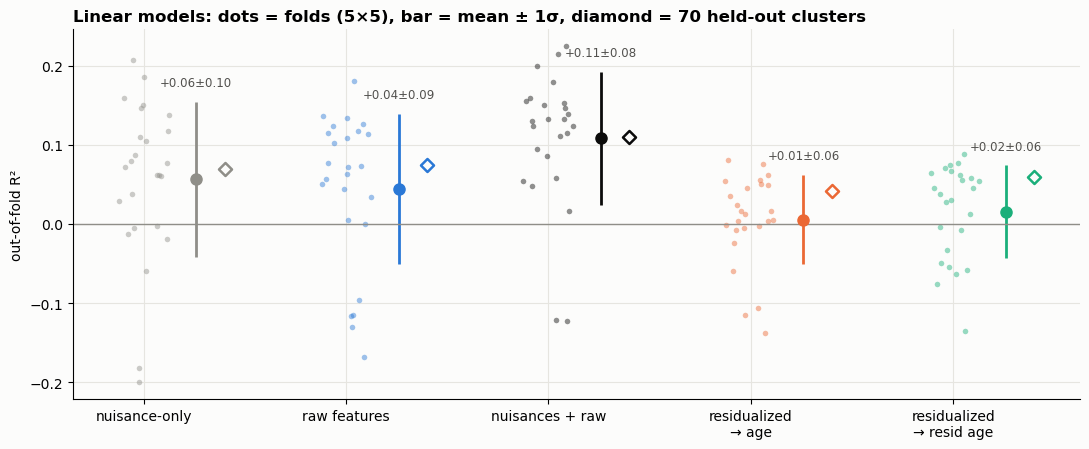

CONCLUSION —
  Residualized features alone: CV R² +0.005 ± 0.056, holdout +0.042.
  Partial R² (both sides residualized): CV +0.015 ± 0.058, holdout +0.059.


In [7]:
order = list(MODELS)
colours = {'nuisance-only': '#8f8e88', 'raw features': '#2a78d6', 'nuisances + raw': '#0b0b0b',
           'residualized → age': '#eb6834', 'residualized → resid age': '#1baf7a'}
fig, ax = plt.subplots(figsize=(11, 4.6))
jr = np.random.default_rng(1)
for k, name in enumerate(order):
    f = folds[name]
    ax.scatter(k + jr.uniform(-.13, .13, len(f)), f, s=16, color=colours[name], alpha=.45, lw=0)
    ax.errorbar(k + .26, f.mean(), yerr=f.std(), fmt='o', color=colours[name], ms=8, elinewidth=2)
    ax.scatter(k + .4, holdout[name], marker='D', s=44, facecolor='#fcfcfb', edgecolor=colours[name], lw=1.8, zorder=3)
    ax.text(k + .26, f.mean() + f.std() + .02, f'{f.mean():+.2f}±{f.std():.2f}', ha='center', fontsize=8.5, color='#52514e')
ax.axhline(0, color='#8f8e88', lw=1)
ax.set_xticks(range(len(order)), [o.replace(' → ', '\n→ ') for o in order])
ax.set_ylabel('out-of-fold R²')
ax.set_title('Linear models: dots = folds (5×5), bar = mean ± 1σ, diamond = 70 held-out clusters',
             loc='left', fontweight='bold')
plt.tight_layout(); plt.show()

hr = holdout['residualized → age']
print('CONCLUSION —')
print(f'  Residualized features alone: CV R² {folds["residualized → age"].mean():+.3f} ± {folds["residualized → age"].std():.3f}, '
      f'holdout {hr:+.3f}.')
print(f'  Partial R² (both sides residualized): CV {folds["residualized → resid age"].mean():+.3f} ± '
      f'{folds["residualized → resid age"].std():.3f}, holdout {holdout["residualized → resid age"]:+.3f}.')

## 6 · Which residualized features the ridge leans on

Standardized ridge coefficients refit on **500 cluster-bootstrap resamples** of the pool, with the
ridge strength fixed at the value chosen on the full pool so the spread reflects the data rather
than the tuning. The fold-to-fold spread is not used: training folds share 75% of their clusters,
which makes it far too narrow. Near-duplicate features (the amplitude family, for example) share
weight between them, so read families rather than single columns.

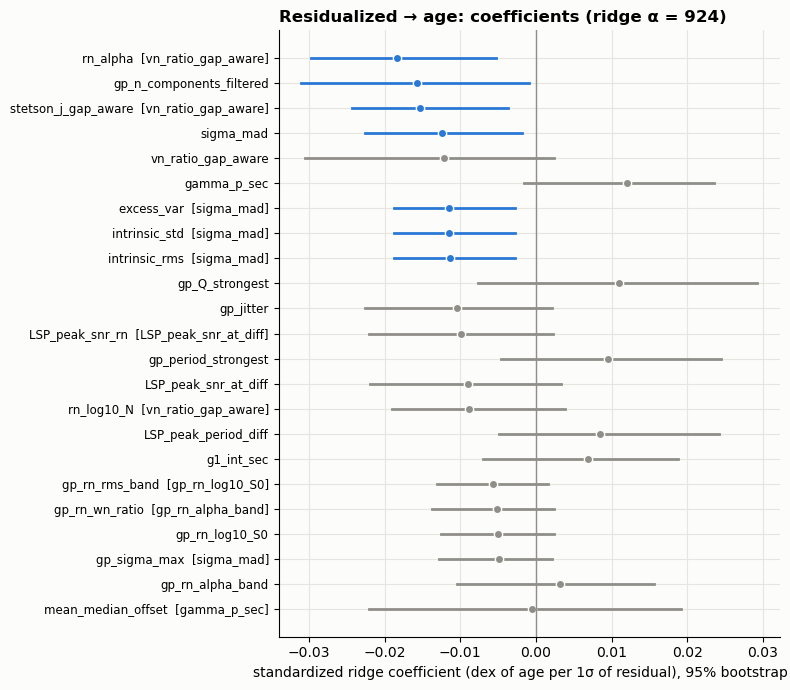

CONCLUSION —
  7 of 23 coefficients have a 95% bootstrap interval excluding zero: rn_alpha, gp_n_components_filtered, stetson_j_gap_aware, sigma_mad, excess_var, intrinsic_std, intrinsic_rms.
  Families share weight, so a family can matter even when no single member is stable.


In [8]:
from sklearn.linear_model import Ridge
Xp, yp_pool = XNF.to_numpy(float)[POOL], y[POOL]
full = make_pipeline(NuisanceResidualizer(N_NUIS), ridge()).fit(Xp, yp_pool)
alpha = full[-1][-1].alpha_
brng = np.random.default_rng(SEED)
boot = []
for _ in range(500):
    i = brng.integers(0, len(POOL), len(POOL))
    m = make_pipeline(NuisanceResidualizer(N_NUIS), StandardScaler(), Ridge(alpha=alpha)).fit(Xp[i], yp_pool[i])
    boot.append(m[-1].coef_)
boot = pd.DataFrame(boot, columns=FEATURES)
point = pd.Series(full[-1][-1].coef_, index=FEATURES)
lo, hi = boot.quantile(.025), boot.quantile(.975)

families = A.feature_families(clusters, FEATURES, threshold=0.8)
fam_of = families.set_index('feature').family.to_dict()
order_c = point.abs().sort_values().index
fig, ax = plt.subplots(figsize=(8, 7))
for k, f in enumerate(order_c):
    c = '#2a78d6' if (lo[f] > 0 or hi[f] < 0) else '#8f8e88'
    ax.plot([lo[f], hi[f]], [k, k], color=c, lw=2)
    ax.plot(point[f], k, 'o', color=c, ms=6, mec='#fcfcfb')
ax.axvline(0, color='#8f8e88', lw=1)
ax.set_yticks(range(len(order_c)), [f'{f}  [{fam_of[f]}]' if fam_of[f] != f else f for f in order_c], fontsize=8.5)
ax.set_xlabel('standardized ridge coefficient (dex of age per 1σ of residual), 95% bootstrap CI')
ax.set_title(f'Residualized → age: coefficients (ridge α = {alpha:.3g})', loc='left', fontweight='bold')
plt.tight_layout(); plt.show()

stable = [f for f in order_c[::-1] if lo[f] > 0 or hi[f] < 0]
print('CONCLUSION —')
print(f'  {len(stable)} of {len(FEATURES)} coefficients have a 95% bootstrap interval excluding zero: '
      f'{", ".join(stable) if stable else "none"}.')
print('  Families share weight, so a family can matter even when no single member is stable.')

## 7 · Result table

In [9]:
out = res_tab.copy()
for nn, tag in [('Freedman–Lane', 'fl'), ('within-galaxy shuffle', 'wg')]:
    for k, row in [(t, t) for t in TESTED] + [('nested gain', 'nuisances + raw')]:
        out.loc[row, f'null_mean_{tag}'] = nulls[nn][k].mean()
        out.loc[row, f'null_sd_{tag}'] = nulls[nn][k].std()
        out.loc[row, f'p_{tag}'] = pvals[nn][k]
out.loc['nuisances + raw', 'nested_gain'] = d_nested.mean()
out.index.name = 'model'
out.to_csv('results_residualized_linear.csv')
display(out.round(3))
print('wrote results_residualized_linear.csv')

print('\nCONCLUSION —')
r, pr = folds['residualized → age'].mean(), pvals['Freedman–Lane']['residualized → age']
print(f'  Light-curve features with the nuisances regressed out predict log age at CV R² {r:+.3f} '
      f'± {folds["residualized → age"].std():.3f} per fold (Freedman–Lane p = {pr:.3f}), '
      f'holdout {holdout["residualized → age"]:+.3f}.')
if pr < 0.05 and r > 0:
    print('  That is detectable light-curve information independent of galaxy and observing setup —')
    print('  but compare its size with the nuisance-only R² before calling it useful.')
else:
    print('  No detectable age information survives once the nuisances are regressed out, consistent')
    print('  with the forest null in notebook 2.')

,cv_r2,cv_r2_sd,holdout_r2,null_mean_fl,null_sd_fl,p_fl,null_mean_wg,null_sd_wg,p_wg,nested_gain
model,,,,,,,,,,
nuisance-only,0.056,0.098,0.070,NaN,NaN,NaN,NaN,NaN,NaN,NaN
raw features,0.044,0.095,0.074,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nuisances + raw,0.108,0.084,0.109,-0.040,0.033,0.003,-0.007,0.014,0.003,0.052
residualized → age,0.005,0.056,0.042,-0.027,0.009,0.003,-0.027,0.009,0.003,NaN
residualized → resid age,0.015,0.058,0.059,-0.031,0.011,0.003,-0.032,0.012,0.003,NaN


wrote results_residualized_linear.csv

CONCLUSION —
  Light-curve features with the nuisances regressed out predict log age at CV R² +0.005 ± 0.056 per fold (Freedman–Lane p = 0.003), holdout +0.042.
  That is detectable light-curve information independent of galaxy and observing setup —
  but compare its size with the nuisance-only R² before calling it useful.
